#**IMPORT LIBRARY**

In [ ]:
import pandas as pd
import numpy as np
from math import sqrt
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
 import warnings
warnings.filterwarnings('ignore')
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
FILE_NAME = "/content/drive/MyDrive/PROJEK KA_KELOMPOK 12/HDR25_Composite_indices_complete_time_series.xlsx"
df_hdi = pd.read_excel(FILE_NAME)
df_hdi

,iso3,country,hdicode,region,hdi_rank_2023,hdi_1990,hdi_1991,hdi_1992,hdi_1993,hdi_1994,...,pop_total_2014,pop_total_2015,pop_total_2016,pop_total_2017,pop_total_2018,pop_total_2019,pop_total_2020,pop_total_2021,pop_total_2022,pop_total_2023
0,AFG,Afghanistan,Low,SA,181.0,0.285,0.291,0.301,0.311,0.305,...,32.792523,33.831764,34.700612,35.688935,36.743039,37.856121,39.068979,40.000412,40.578842,41.454761
1,ALB,Albania,Very High,ECA,71.0,0.654,0.638,0.622,0.624,0.629,...,2.903749,2.898632,2.897867,2.898242,2.894231,2.885009,2.871954,2.849636,2.827608,2.811655
2,DZA,Algeria,High,AS,96.0,0.595,0.596,0.601,0.603,0.603,...,39.205030,40.019529,40.850721,41.689299,42.505035,43.294546,44.042091,44.761099,45.477390,46.164219
3,AND,Andorra,Very High,NaN,32.0,NaN,NaN,NaN,NaN,NaN,...,0.073737,0.072174,0.072181,0.073762,0.075162,0.076473,0.077380,0.078364,0.079705,0.080856
4,AGO,Angola,Medium,SSA,148.0,NaN,NaN,NaN,NaN,NaN,...,27.160770,28.157798,29.183070,30.234839,31.297155,32.375633,33.451132,34.532429,35.635029,36.749906
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201,ZZG.ECA,Europe and Central Asia,NaN,NaN,NaN,0.674,0.671,0.664,0.659,0.654,...,237.933850,240.937124,243.649817,246.131011,248.450885,250.382485,252.050998,253.404866,251.911694,250.300624
202,ZZH.LAC,Latin America and the Caribbean,NaN,NaN,NaN,0.648,0.653,0.657,0.661,0.666,...,608.767281,614.831634,620.753858,626.503607,632.005592,637.185739,641.737540,645.501309,649.425289,653.952733
203,ZZI.SA,South Asia,NaN,NaN,NaN,0.454,0.458,0.464,0.468,0.472,...,1849.167918,1871.872058,1894.465346,1917.144604,1939.537762,1961.729204,1983.510394,2003.263428,2022.467288,2043.083160
204,ZZJ.SSA,Sub-Saharan Africa,NaN,NaN,NaN,0.405,0.409,0.408,0.411,0.413,...,945.842319,971.462925,997.258713,1023.353059,1050.355450,1077.776785,1105.614070,1133.710593,1162.042581,1191.521675


**PENAMAAN**

In [ ]:
id_vars = ['iso3', 'country', 'region'] # MELTING (UNPIVOTING)

# Fitur Numerik + Target HDI
value_vars_prefixes = [
    'hdi_', 'le_', 'eys_', 'mys_', 'gnipc_', # Core
    'le_f_', 'le_m_', 'eys_f_', 'eys_m_', 'mys_f_', 'mys_m_', 'gni_pc_f_', 'gni_pc_m_', # Gender
    'ihdi_', 'coef_ineq_', 'loss_', # Inequality
    'pop_total_' # Demographic
]

# Ambil semua kolom yang cocok dengan prefix tahun
columns_to_melt = []
for prefix in value_vars_prefixes:
    columns_to_melt.extend([col for col in df_hdi.columns if col.startswith(prefix) and col.split('_')[-1].isdigit()])
df_slim = df_hdi[id_vars + columns_to_melt]

# Melt DataFrame
df_long = pd.melt(
    df_slim,
    id_vars=id_vars,
    value_vars=[col for col in df_slim.columns if col not in id_vars],
    var_name='variable_year',
    value_name='value'
)

# Ekstraksi Tahun dan Pivot kembali
df_long[['variable', 'year']] = df_long['variable_year'].str.rsplit('_', n=1, expand=True)
df_long['year'] = pd.to_numeric(df_long['year'], errors='coerce')

df_final = df_long.pivot_table(
    index=['iso3', 'country', 'region', 'year'],
    columns='variable',
    values='value',
    aggfunc='first'
).reset_index().rename(columns={'gnipc': 'gni_per_capita', 'loss': 'hdi_loss_ineq'})
df_final

variable,iso3,country,region,year,coef_ineq,eys,eys_f,eys_m,gni_pc_f,gni_pc_m,...,hdi_rank,ihdi,le,le_f,le_m,hdi_loss_ineq,mys,mys_f,mys_m,pop_total
0,AFG,Afghanistan,SA,1990,NaN,2.936460,2.117230,4.532768,NaN,NaN,...,NaN,NaN,45.118,47.703,42.712,NaN,0.871962,0.201659,1.493952,12.045660
1,AFG,Afghanistan,SA,1991,NaN,3.228456,2.246242,4.768261,NaN,NaN,...,NaN,NaN,45.521,48.282,42.959,NaN,0.915267,0.218944,1.578809,12.238879
2,AFG,Afghanistan,SA,1992,NaN,3.520452,2.383115,5.015989,NaN,NaN,...,NaN,NaN,46.569,49.607,43.765,NaN,0.958573,0.236229,1.663665,13.278973
3,AFG,Afghanistan,SA,1993,NaN,3.812448,2.528328,5.276587,NaN,NaN,...,NaN,NaN,51.021,52.296,49.755,NaN,1.001878,0.253514,1.748522,14.943172
4,AFG,Afghanistan,SA,1994,NaN,4.104445,2.682390,5.550723,NaN,NaN,...,NaN,NaN,50.969,53.135,48.883,NaN,1.045184,0.270800,1.833378,16.250795
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5129,ZWE,Zimbabwe,SSA,2019,30.610717,10.993813,10.651119,11.359176,2844.843086,3914.474693,...,NaN,0.393,61.060,63.049,58.830,32.705479,8.687460,8.070020,9.462640,15.271368
5130,ZWE,Zimbabwe,SSA,2020,30.307406,11.025587,10.695159,11.375836,2571.697218,3519.091272,...,NaN,0.393,61.530,63.747,59.091,32.474227,8.808313,8.191878,9.591444,15.526889
5131,ZWE,Zimbabwe,SSA,2021,30.147263,11.057453,10.739381,11.392520,3100.435476,3344.835048,...,NaN,0.393,60.135,62.289,57.717,32.358003,8.930847,8.315577,9.722002,15.797210
5132,ZWE,Zimbabwe,SSA,2022,30.139826,11.057453,10.739381,11.392520,2920.665300,3825.514391,...,NaN,0.402,62.360,64.544,59.880,32.323232,8.930847,8.315577,9.722002,16.069056


# **PREPROCESSING**

In [ ]:
# ambil negara di benua asia
asia_regions = ["SA", "EAP", "ECA"]
df_asia = df_final[df_final['region'].isin(asia_regions)].copy()
df_asia['country'] = df_asia['country'].astype(str)  # pastikan string
df_asia['country'] = df_asia['country'].str.strip()  # hapus spasi awal/akhir
df_asia['country'] = df_asia['country'].str.replace(r'[^a-zA-Z\s]', '', regex=True)  # hapus simbol/tanda aneh
df_asia['country'] = df_asia['country'].str.title()  # huruf kapital di awal tiap kata

# cek duplikat
duplikat = df_asia[df_asia.duplicated(subset=['country','year'], keep=False)]
print(f"Jumlah duplikat country-year: {len(duplikat)}")

target = 'hdi'
fitur_inti = ['le', 'eys', 'mys', 'gni_per_capita']

# Drop baris tanpa nilai Target atau fitur inti
df_asia.dropna(subset=[target] + fitur_inti, inplace=True)
df_asia

Jumlah duplikat country-year: 0


variable,iso3,country,region,year,coef_ineq,eys,eys_f,eys_m,gni_pc_f,gni_pc_m,...,hdi_rank,ihdi,le,le_f,le_m,hdi_loss_ineq,mys,mys_f,mys_m,pop_total
0,AFG,Afghanistan,SA,1990,NaN,2.936460,2.117230,4.532768,NaN,NaN,...,NaN,NaN,45.118,47.703,42.712,NaN,0.871962,0.201659,1.493952,12.045660
1,AFG,Afghanistan,SA,1991,NaN,3.228456,2.246242,4.768261,NaN,NaN,...,NaN,NaN,45.521,48.282,42.959,NaN,0.915267,0.218944,1.578809,12.238879
2,AFG,Afghanistan,SA,1992,NaN,3.520452,2.383115,5.015989,NaN,NaN,...,NaN,NaN,46.569,49.607,43.765,NaN,0.958573,0.236229,1.663665,13.278973
3,AFG,Afghanistan,SA,1993,NaN,3.812448,2.528328,5.276587,NaN,NaN,...,NaN,NaN,51.021,52.296,49.755,NaN,1.001878,0.253514,1.748522,14.943172
4,AFG,Afghanistan,SA,1994,NaN,4.104445,2.682390,5.550723,NaN,NaN,...,NaN,NaN,50.969,53.135,48.883,NaN,1.045184,0.270800,1.833378,16.250795
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4993,WSM,Samoa,EAP,2019,14.365038,12.395067,12.935545,11.899959,4358.877932,8965.151244,...,NaN,0.605,70.269,72.195,68.469,14.548023,11.401800,11.773020,11.021990,0.209780
4994,WSM,Samoa,EAP,2020,13.973905,12.436400,12.988140,11.930620,4139.489085,8661.639770,...,NaN,0.607,70.727,72.881,68.757,14.265537,11.367340,11.768403,10.957149,0.211944
4995,WSM,Samoa,EAP,2021,13.838905,12.436400,12.988140,11.930620,3813.265350,8142.317307,...,NaN,0.606,71.096,73.016,69.306,14.164306,11.332984,11.763787,10.892689,0.213779
4996,WSM,Samoa,EAP,2022,13.764995,12.436400,12.988140,11.930620,4103.556501,6900.185944,...,NaN,0.604,71.550,73.486,69.737,14.082504,11.332984,11.763787,10.892689,0.215260


In [ ]:
df_asia.isna().sum()

,0
variable,
iso3,0
country,0
region,0
year,0
coef_ineq,930
eys,0
eys_f,84
eys_m,84
gni_pc_f,160


In [ ]:
df_asia = df_asia.to_csv('hdi_preprocessed_asia.csv', index=False)

# **EDA**

In [ ]:
df_asia = pd.read_csv('hdi_preprocessed_asia.csv')
df_asia.describe()

,year,coef_ineq,eys,eys_f,eys_m,gni_pc_f,gni_pc_m,gni_per_capita,hdi,hdi_f,...,hdi_rank,ihdi,le,le_f,le_m,hdi_loss_ineq,mys,mys_f,mys_m,pop_total
count,1503.000000,573.000000,1503.000000,1419.000000,1419.000000,1343.000000,1343.000000,1503.000000,1503.000000,1267.000000,...,51.000000,573.000000,1503.000000,1503.000000,1503.000000,573.000000,1503.000000,1473.000000,1473.000000,1503.000000
mean,2008.106454,18.191502,11.895133,11.926624,12.012633,9658.443629,17715.710338,12919.783254,0.664400,0.655026,...,103.803922,0.592363,69.043988,71.992683,66.214045,18.586092,8.037702,7.577477,8.502145,85.004978
std,9.404399,7.995725,2.570156,3.000290,2.290170,13848.505876,22415.400288,17425.604362,0.117408,0.124885,...,37.003794,0.127126,5.587897,5.946036,5.420300,8.175166,2.964331,3.281978,2.668253,259.535782
min,1990.000000,6.338465,2.936460,2.117230,4.532768,557.532819,1320.890071,657.863185,0.285000,0.256890,...,13.000000,0.297000,45.118000,47.703000,42.712000,6.432039,0.871962,0.201659,1.493952,0.008798
25%,2001.000000,12.102173,10.777340,10.475291,11.086235,2991.764285,5996.721936,4204.921736,0.596500,0.583052,...,74.500000,0.476000,65.513500,68.251500,62.689500,12.530120,5.495099,4.850586,6.330068,1.045606
50%,2009.000000,16.363067,12.001101,12.334850,11.979849,5480.023437,10894.858440,7747.289846,0.678000,0.668831,...,104.000000,0.620000,69.303000,72.642000,66.147000,16.666667,8.529891,8.185980,8.846200,7.227202
75%,2016.000000,23.431763,13.440335,13.830840,13.291700,10800.205955,20967.467995,15079.822620,0.753000,0.752276,...,130.000000,0.695000,73.040500,76.442500,69.590000,23.888183,10.595000,10.424460,10.810000,47.173733
max,2023.000000,35.845718,19.830799,19.737740,19.924150,103195.352400,128666.538700,112141.234300,0.948000,0.944938,...,181.000000,0.825000,83.736000,86.236000,81.458000,36.129032,13.299035,13.330156,13.341110,1438.069596


In [ ]:
features = [
    'eys', 'eys_f',
    'eys_m',
    'gni_pc_f',
    'gni_pc_m',
    'gni_per_capita',
    'le',
    'le_f',
    'le_m',
    'hdi_loss_ineq',
    'mys',
    'mys_f',
    'mys_m',
    'pop_total',
    'hdi_f',
    'hdi_m',
    'hdi_rank',
    'ihdi',
    'coef_ineq'
]

target = 'hdi'

## **DISTRIBUSI SETIAP FITUR**

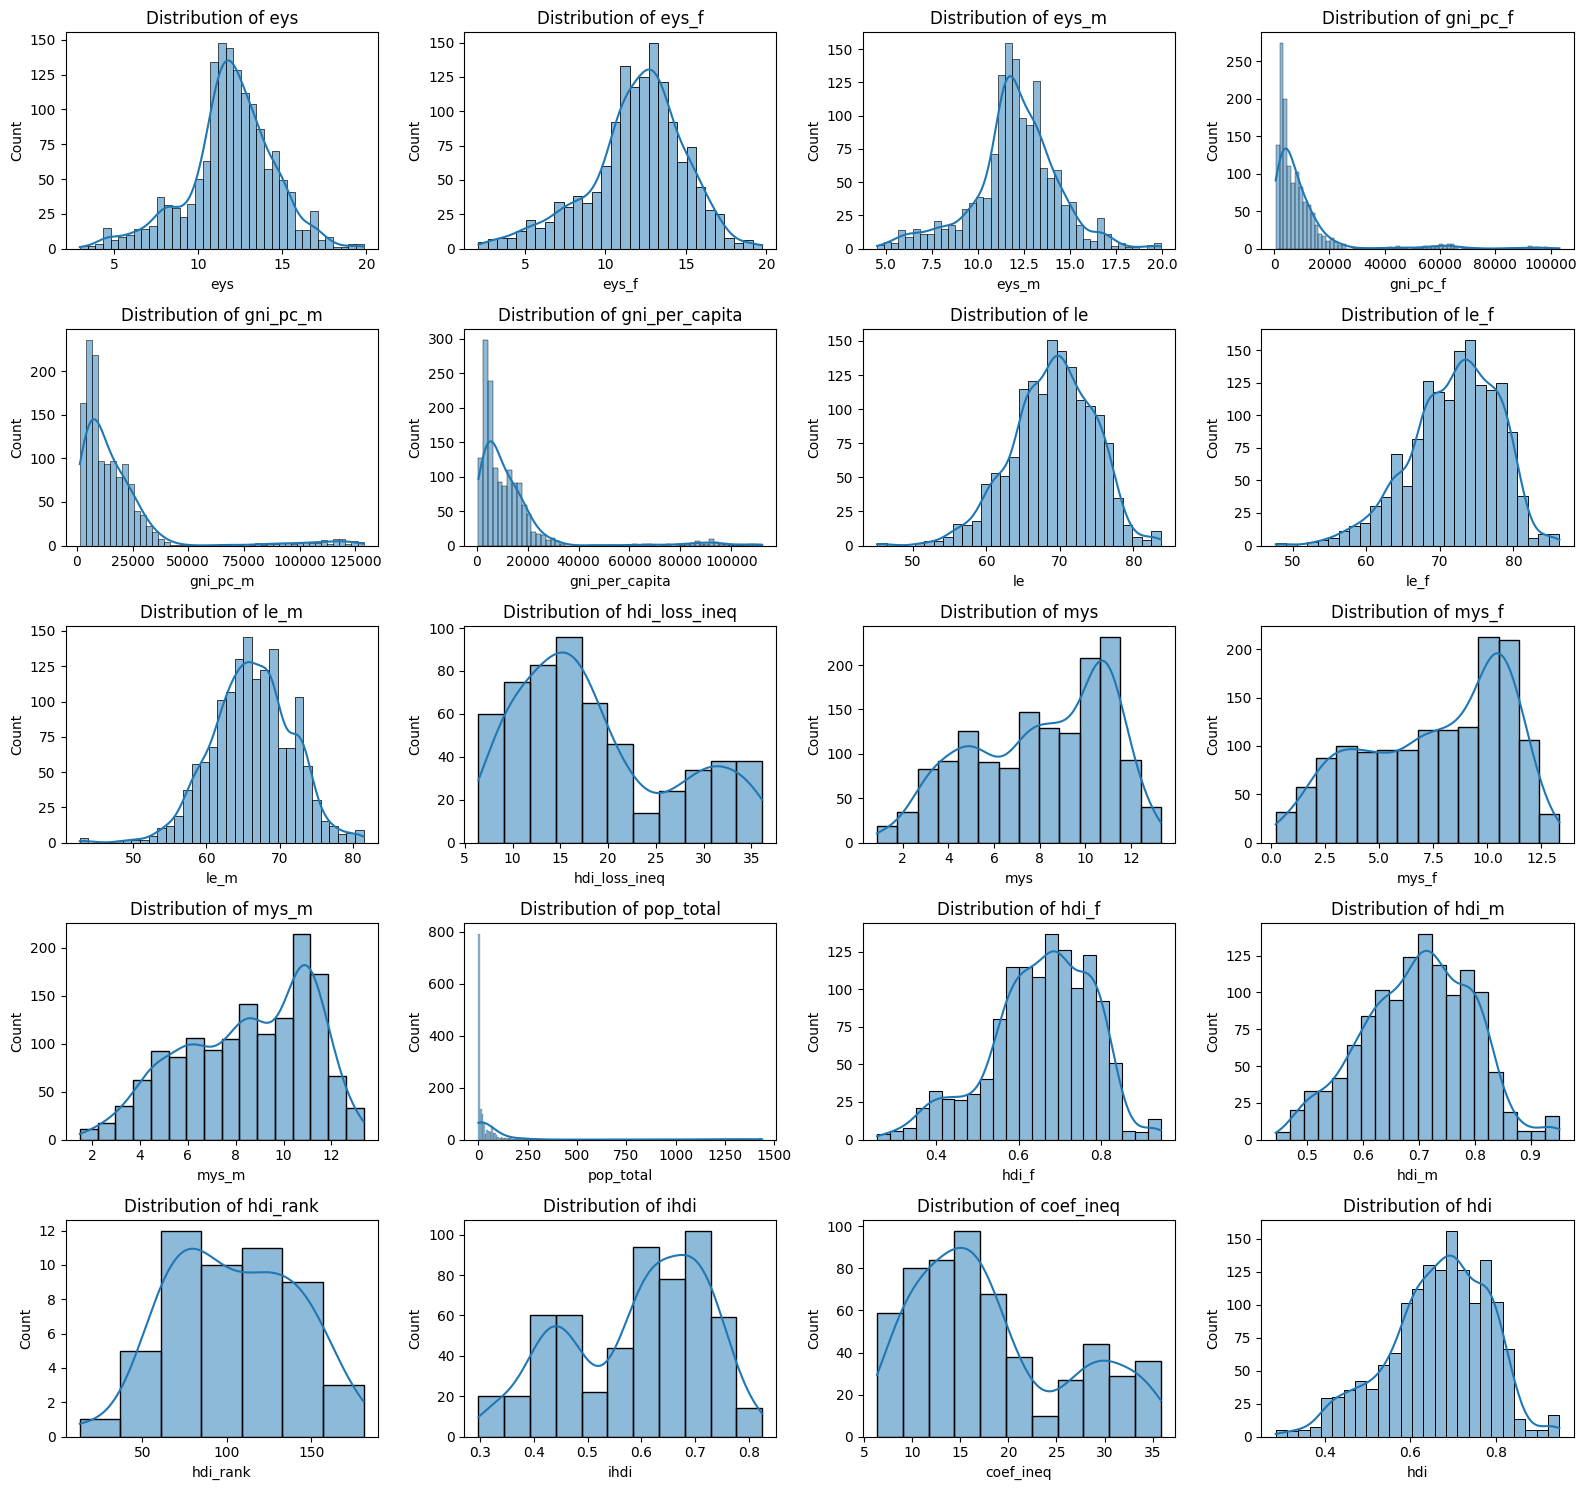

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16,15)) # Mengubah tinggi figure untuk 5 baris plot
for i, col in enumerate(features + [target]):
    # Mengubah grid subplot dari (4,4) menjadi (5,4) agar bisa menampung 20 plot
    plt.subplot(5,4,i+1)
    sns.histplot(df_asia[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

## **KORELASI ANTARA HDI DENGAN SEMUA FITUR**

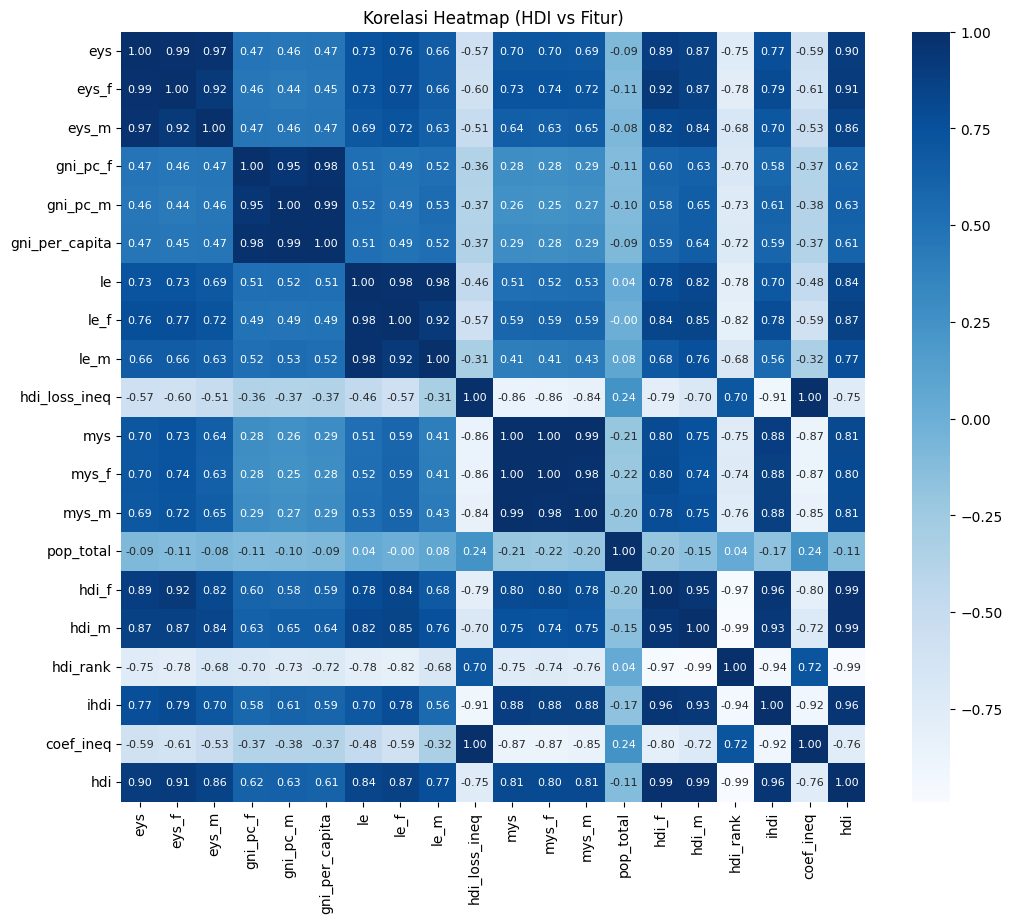

In [ ]:
corr_cols = features + [target]
plt.figure(figsize=(12,10)) # Meningkatkan ukuran figure lebih lanjut
sns.heatmap(df_asia[corr_cols].corr(), annot=True, cmap='Blues', fmt=".2f", annot_kws={"fontsize":8}) # Mengurangi ukuran font anotasi dan membatasi presisi angka
plt.title('Korelasi Heatmap (HDI vs Fitur)')
plt.show()

**HDI - SA (South Asia)**

In [ ]:
# Filter Benua SA
df_eap = df_asia[df_asia['region'] == 'SA']

# Nilai HDI pernegara tiap tahunnya
fig = px.line(
    df_eap,
    x='year',
    y='hdi',
    color='country',
    line_shape='linear',
    hover_name='country',
    markers=True
)

fig.update_layout(
    title={
        'text': 'HDI Trend – SOUTH ASIA (SA)',
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    xaxis_title='Year',
    yaxis_title='HDI',
    legend_title='Country'
)

fig.show()

**HDI - ECA (Europe & Central Asia)**

In [ ]:
# Filter Benua ECA
df_eap = df_asia[df_asia['region'] == 'ECA']

# Nilai HDI pernegara tiap tahunnya
fig = px.line(
    df_eap,
    x='year',
    y='hdi',
    color='country',
    line_shape='linear',
    hover_name='country',
    markers=True
)

fig.update_layout(
    title={
        'text': 'HDI Trend – Europe - Central Asia (ECA)',
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    xaxis_title='Year',
    yaxis_title='HDI',
    legend_title='Country'
)

fig.show()

****HDI - ECA (East Asia and Pacific)****

In [ ]:
# Filter Benua EAP
df_eap = df_asia[df_asia['region'] == 'EAP']

# Nilai HDI pernegara tiap tahunnya
fig = px.line(
    df_eap,
    x='year',
    y='hdi',
    color='country',
    line_shape='linear',
    hover_name='country',
    markers=True
)

fig.update_layout(
    title={
        'text': 'HDI Trend – East Asia & Pacific (EAP)',
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    xaxis_title='Year',
    yaxis_title='HDI',
    legend_title='Country'
)

fig.show()

**HDI - SEMUA NEGARA**

In [ ]:
# Nilai HDI Seluruh Negara di ASIA tiap tahunnya
fig = px.line(
    df_asia,
    x='year',
    y='hdi',
    color='country',
    hover_name='country',
    line_shape='linear',
    markers=False
)

fig.update_layout(
    title={
        'text': "Tren HDI Semua Negara (1990–2023)",
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    xaxis_title="Tahun",
    yaxis_title="HDI",
    legend_title="Country",
    height=700,
    width=1200
)

fig.show()

# **MODEL**


In [ ]:
# Fitur (X) dan Target (y)
fitur = [
    'eys', 'eys_f', 'eys_m',
    'gni_pc_f', 'gni_pc_m', 'gni_per_capita',
    'le', 'le_f', 'le_m',
    'hdi_loss_ineq',
    'mys', 'mys_f', 'mys_m',
    'pop_total'
]
target = 'hdi'

# fungsi split data training (80%) & testing (20%)
def split_data(df, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    jumlah_total_sampel = len(df)
    indeks = np.arange(jumlah_total_sampel)
    np.random.shuffle(indeks)
    jumlah_sampel_test = int(jumlah_total_sampel * test_size)

    indeks_test = indeks[:jumlah_sampel_test]
    indeks_train = indeks[jumlah_sampel_test:]

    df_train = df.iloc[indeks_train].reset_index(drop=True)
    df_test = df.iloc[indeks_test].reset_index(drop=True)

    return df_train, df_test

# split data dengan fungsi tersebut
df_train, df_test = split_data(df_asia, test_size=0.2, random_state=42)

# Daftar Kolom untuk Dibersihkan
seluruh_fitur_numerik = [
    'le', 'eys', 'mys', 'gni_per_capita',
    'le_f', 'le_m', 'eys_f', 'eys_m', 'mys_f', 'mys_m',
    'gni_pc_f', 'gni_pc_m',
    'ihdi', 'coef_ineq', 'hdi_loss_ineq',
    'pop_total', 'year',
    'hdi_f', 'hdi_m', 'hdi_rank'
]

# Saring daftar tadi: ambil kolom angka tanpa kolom 'target', 'tahun', dan 'fitur inti'
kolom_NaN = [
    kolom for kolom in seluruh_fitur_numerik
    if kolom not in fitur_inti and kolom != 'year' and kolom != target
]

# Mengisi NaN
regional_median_train = df_train.groupby('region')[kolom_NaN].median()          # Kita hitung nilai tengah (median) per wilayah (region) dari data training.

# Isi NaN di Data Training
for fitur_col in kolom_NaN:
    df_train[fitur_col] = df_train.apply(
        lambda row: regional_median_train.loc[row['region'], fitur_col]             # isi pakai median wilayah row tersebut.
        if pd.isnull(row[fitur_col]) else row[fitur_col],
        axis=1
    )
    df_train[fitur_col] = df_train[fitur_col].fillna(df_train[fitur_col].median()) # kalau median wilayah masih kosong juga, isi pakai median global (rata-rata umum)

# Isi NaN di Data Testing
for fitur_col in kolom_NaN:
    df_test[fitur_col] = df_test.apply(
        lambda row: regional_median_train.loc[row['region'], fitur_col]         # Data testing NaN ini diisi pakai contekan (median) dari Data Training tadi.
        if pd.isnull(row[fitur_col]) else row[fitur_col],
        axis=1
    )
    df_test[fitur_col] = df_test[fitur_col].fillna(df_train[fitur_col].median()) # Fallback ke median global punya data training

X_train = df_train[fitur].values
y_train = df_train[target].values
X_test = df_test[fitur].values
y_test = df_test[target].values

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Ukuran X_train: (1203, 14)
Ukuran X_test: (300, 14)
Ukuran y_train: (1203,)
Ukuran y_test: (300,)


## DECISION TREE

Referensi ytb: https://youtu.be/P2ZB8c5Ha1Q?si=WQXAyMEvvQHF8EMu

In [ ]:
class Node():
  def __init__(self, indeks_fitur=None, ambang_batas=None, anak_kiri=None, anak_kanan=None, variansi_reduksi=None, value=None):
    self.indeks_fitur = indeks_fitur
    self.ambang_batas = ambang_batas
    self.anak_kiri = anak_kiri
    self.anak_kanan = anak_kanan
    self.variansi_reduksi = variansi_reduksi
    self.value = value

In [ ]:
class DecisionTreeRegressor():
  def __init__(self, min_samples_split=2, maks_kedalaman=100):
    # Inisialisasi parameter pohon
    self.akar = None
    self.min_samples_split = min_samples_split
    self.maks_kedalaman = maks_kedalaman

  def bangun_pohon(self, dataset, indeks_kedalaman=0):
    # Proses membangun pohon
    X, Y = dataset[:,:-1], dataset[:,-1]
    jumlah_sampel, jumlah_fitur = np.shape(X)

    # Kondisi berhenti lanjut buat node daun
    if jumlah_sampel < self.min_samples_split or indeks_kedalaman >= self.maks_kedalaman:
        nilai_daun = self.hitung_nilai_daun(Y)
        return Node(value=nilai_daun)

    split_terbaik = self.cari_split_terbaik(dataset, jumlah_sampel, jumlah_fitur)# Cari split terbaik

    # Jika ada split bagus lanjut bangun subtree
    if split_terbaik and "variansi_reduksi" in split_terbaik and split_terbaik["variansi_reduksi"] > 0:
        bobot_kiri = self.bangun_pohon(split_terbaik["dataset_kiri"], indeks_kedalaman+1)
        bobot_kanan = self.bangun_pohon(split_terbaik["dataset_kanan"], indeks_kedalaman+1)
        return Node(split_terbaik["indeks_fitur"], split_terbaik["ambang_batas"],
                    bobot_kiri, bobot_kanan, split_terbaik["variansi_reduksi"])
    else:
        nilai_daun = self.hitung_nilai_daun(Y)                                  # Jika tidak ada split ke node daun
        return Node(value=nilai_daun)

  def variansi_reduksi(self, induks, anak_kiri, anak_kanan):                    # Hitung seberapa besar variansi berkurang setelah split
    bobot_kiri = len(anak_kiri) / len(induks)
    bobot_kanan = len(anak_kanan) / len(induks)
    reduksi = np.var(induks) - (bobot_kiri * np.var(anak_kiri) + bobot_kanan * np.var(anak_kanan))
    return reduksi

  def hitung_nilai_daun(self, Y):# Nilai daun = rata-rata target
    val = np.mean(Y)
    return val

  def split(self, dataset, indeks_fitur, ambang_batas):# Memisahkan dataset berdasarkan ambang batas fitur
    dataset_kiri = np.array([row for row in dataset if row[indeks_fitur]<=ambang_batas])
    dataset_kanan = np.array([row for row in dataset if row[indeks_fitur]>ambang_batas])
    return dataset_kiri, dataset_kanan

  def cari_split_terbaik(self, dataset, jumlah_sampel, jumlah_fitur):    # Cari kombinasi fitur dan ambang batas dengan reduksi variansi terbesar
    split_terbaik = {}
    maks_reduksi_variansi= -float("inf")
    for indeks_fitur in range(jumlah_fitur):
      nilai_fitur = dataset[:, indeks_fitur]
      ambang_batas_potensial = np.unique(nilai_fitur)
      for ambang_batas in ambang_batas_potensial:
        dataset_kiri, dataset_kanan = self.split(dataset, indeks_fitur, ambang_batas)
        if len(dataset_kiri)>0 and len(dataset_kanan)>0:
          y, left_y, right_y = dataset[:, -1], dataset_kiri[:, -1], dataset_kanan[:, -1]
          indeks_variansi_reduksi = self.variansi_reduksi(y, left_y, right_y)
          if indeks_variansi_reduksi>maks_reduksi_variansi:
            split_terbaik["indeks_fitur"] = indeks_fitur
            split_terbaik["ambang_batas"] = ambang_batas
            split_terbaik["dataset_kiri"] =dataset_kiri
            split_terbaik["dataset_kanan"] = dataset_kanan
            split_terbaik["variansi_reduksi"] = indeks_variansi_reduksi
            maks_reduksi_variansi = indeks_variansi_reduksi
    return split_terbaik

  def pohon(self, pohon=None, indent=" "):
      # #Cetak struktur pohon (visualisasi teks)
      if not pohon:
          pohon = self.akar
      if pohon.value is not None:
          print(pohon.value)
      else:
          print (f"Fitur X_{pohon.indeks_fitur} <= {pohon.ambang_batas}? Reduksi Variansi: {pohon.variansi_reduksi}")
          print("%skiri:" % (indent), end="")
          self.pohon(pohon.anak_kiri, indent + indent)
          print("%skanan:" % (indent), end="")
          self.pohon(pohon.anak_kanan, indent + indent)

  def fit(self, X, Y):
      # Latih model dengan data (bangun pohon dari dataset)
      Y_reshaped = Y.reshape(-1, 1)
      dataset = np.concatenate((X, Y_reshaped), axis=1)
      self.akar = self.bangun_pohon(dataset)

  def bangun_prediksi(self, x, pohon):
      # Proses prediksi rekursif berdasarkan pohon
      if pohon.value!=None: return pohon.value
      feature_val = x[pohon.indeks_fitur]
      if feature_val<=pohon.ambang_batas:
          return self.bangun_prediksi(x, pohon.anak_kiri)
      else:
          return self.bangun_prediksi(x, pohon.anak_kanan)

  def prediksi(self, X):
    # Prediksi untuk banyak sampel
    prediksi = [self.bangun_prediksi(x, self.akar) for x in X]
    return prediksi

In [ ]:
regresor = DecisionTreeRegressor(min_samples_split=3, maks_kedalaman=3)
regresor.fit(X_train, y_train)
regresor.pohon()

Fitur X_5 <= 5395.768931? Reduksi Variansi: 0.007969100641199748
 kiri:Fitur X_0 <= 8.942250859? Reduksi Variansi: 0.004903023388812866
  kiri:Fitur X_11 <= 2.812969304? Reduksi Variansi: 0.0018875149083492238
    kiri:0.4141720430107528
    kanan:0.5033220338983051
  kanan:Fitur X_11 <= 5.509549573? Reduksi Variansi: 0.001252539097367466
    kiri:0.5532905982905982
    kanan:0.6253117647058823
 kanan:Fitur X_3 <= 10818.76239? Reduksi Variansi: 0.002560391276535191
  kiri:Fitur X_10 <= 9.088997815? Reduksi Variansi: 0.0009549654812367968
    kiri:0.663248031496063
    kanan:0.7250609756097561
  kanan:Fitur X_1 <= 16.52611923? Reduksi Variansi: 0.0011276257399481827
    kiri:0.7873722943722943
    kanan:0.8889090909090908


In [ ]:
y_pred = regresor.prediksi(X_test)
np.sqrt(np.mean((y_pred-y_test)**2))

# Hitung R²
def dt_r2_score(y_asli, y_pred):
    y_mean = np.mean(y_asli)
    ss_total = np.sum((y_asli - y_mean) ** 2)
    ss_res = np.sum((y_asli - y_pred) ** 2)
    if ss_total == 0:
        return 0.0

    r2 = 1 - (ss_res / ss_total)
    return r2

# Hitung MSE
def dt_mse_score(y_asli, y_pred):
    errors = (y_asli - y_pred) ** 2
    mse = np.mean(errors)
    return mse

dt_r2 = dt_r2_score(y_test, y_pred)
print(f"R²: {dt_r2}")
dt_mse = dt_mse_score(y_test, y_pred)
print(f"MSE: {dt_mse}")

R²: 0.8860155249882632
MSE: 0.0014797821241440815


In [ ]:
# Hasil Prediksi dengan Data Testing
np.set_printoptions(precision=4, suppress=True, linewidth=200)
print("Prediksi HDI:", np.array(y_pred))
print("HDI Asli :", y_test)

Prediksi HDI: [0.7251 0.6253 0.7874 0.6632 0.6632 0.4142 0.6632 0.6632 0.6253 0.6253 0.4142 0.5033 0.5533 0.5533 0.6632 0.5533 0.8889 0.4142 0.7874 0.7874 0.7251 0.6632 0.7874 0.7874 0.5533 0.7251 0.5533 0.8889
 0.5533 0.6253 0.6253 0.7251 0.5033 0.7874 0.6632 0.7874 0.7874 0.7251 0.6253 0.6253 0.6632 0.7874 0.6632 0.5533 0.6632 0.7874 0.4142 0.5533 0.6632 0.7251 0.7251 0.6253 0.4142 0.7251 0.7874 0.6253
 0.7874 0.6253 0.6632 0.6632 0.6253 0.6632 0.5533 0.7874 0.7874 0.6253 0.7874 0.4142 0.6632 0.7874 0.7874 0.4142 0.5533 0.7874 0.7874 0.6632 0.4142 0.8889 0.6632 0.6632 0.6632 0.6253 0.5533 0.7874
 0.5533 0.7251 0.7874 0.8889 0.6632 0.7874 0.7874 0.6632 0.6253 0.7874 0.7874 0.5533 0.7251 0.5533 0.7251 0.7251 0.6632 0.6253 0.7251 0.7251 0.4142 0.6632 0.6632 0.7874 0.7251 0.6253 0.5533 0.8889
 0.4142 0.7874 0.7251 0.4142 0.5533 0.6253 0.7874 0.6632 0.7251 0.8889 0.7251 0.6632 0.6632 0.5533 0.5033 0.4142 0.6253 0.7251 0.7251 0.6632 0.6253 0.7251 0.6632 0.6632 0.4142 0.7874 0.6253 0.6632
 

## RANDOM FOREST


In [ ]:
# Model Random Forest
def bootstrap_sample(X, y):
  jumlah_sampel = X.shape[0]
  indeks_acak = np.random.choice(jumlah_sampel, size=jumlah_sampel, replace=True)
  return X[indeks_acak], y[indeks_acak]

class RandomForest:
  def __init__(self, jumlah_pohon=100, min_samples_split=2, maks_kedalaman=2):
    self.jumlah_pohon = jumlah_pohon
    self.min_samples_split = min_samples_split
    self.maks_kedalaman = maks_kedalaman
    self.pohon = []

  def fit(self, X, y):
    self.pohon = []
    for _ in range(self.jumlah_pohon):
      hutan= DecisionTreeRegressor(min_samples_split=self.min_samples_split,
      maks_kedalaman=self.maks_kedalaman)
      X_samples, y_sample = bootstrap_sample(X, y)
      # train tree
      hutan.fit(X_samples, y_sample)
      self.pohon.append(hutan)

  def prediksi(self, X):
    prediksi_hutan = np.array([hutan.prediksi(X) for hutan in self.pohon])

    y_pred = np.mean(prediksi_hutan, axis=0)

    return y_pred

In [ ]:
def rf_mse(y_asli, y_pred):
  return np.mean((y_asli - y_pred)**2)

def rf_rmse(y_asli, y_pred):
  return np.sqrt(rf_mse(y_asli, y_pred))

def rf_r2_score(y_asli, y_pred):
  mean_y = np.mean(y_asli)
  ss_total = np.sum((y_asli - mean_y)**2)
  ss_res = np.sum((y_asli - y_pred)**2)
  if ss_total == 0:
      return 0.0
  r2 = 1 - (ss_res / ss_total)
  return r2

In [ ]:
random_forest = RandomForest(jumlah_pohon=30, maks_kedalaman=4, min_samples_split=3)

# training
random_forest.fit(X_train, y_train)

# prediksi
y_pred_random_forest = random_forest.prediksi(X_test)

print("MSE : ", rf_mse(y_test, y_pred_random_forest))
print("RMSE : ", rf_rmse(y_test, y_pred_random_forest))
print("R2 Score : ", rf_r2_score(y_test, y_pred_random_forest))

MSE :  0.00041632584344643086
RMSE :  0.020404064385470627
R2 Score :  0.9679313042610863


In [ ]:
# Hasil Prediksi dengan Data Testing
np.set_printoptions(precision=4, suppress=True, linewidth=200)
print("Prediksi HDI (Random Forest):", np.array(y_pred_random_forest))
print("HDI Asli :", y_test.flatten())

Prediksi HDI (Random Forest): [0.7025 0.6241 0.7751 0.6879 0.7033 0.439  0.6524 0.6352 0.619  0.6108 0.4001 0.5015 0.5962 0.5662 0.723  0.5802 0.8201 0.4327 0.8118 0.8006 0.6908 0.6591 0.7825 0.8118 0.5393 0.7232 0.556  0.8171
 0.5747 0.6475 0.6015 0.7123 0.4906 0.7801 0.6816 0.7634 0.7801 0.719  0.5994 0.6457 0.6659 0.7909 0.63   0.5946 0.7005 0.7898 0.4465 0.5013 0.6426 0.7615 0.7316 0.6203 0.4478 0.7061 0.7828 0.6377
 0.8118 0.6175 0.6961 0.6679 0.6187 0.698  0.5763 0.7894 0.7884 0.6377 0.8243 0.4405 0.6929 0.7999 0.8021 0.4205 0.5751 0.7218 0.7801 0.6949 0.4528 0.8504 0.6618 0.6584 0.6512 0.6377 0.5057 0.7831
 0.5789 0.7028 0.7801 0.9289 0.6964 0.7886 0.76   0.6912 0.6055 0.7815 0.773  0.5249 0.7633 0.5815 0.7061 0.7633 0.6672 0.6475 0.7004 0.7441 0.439  0.6991 0.6728 0.7622 0.7028 0.6377 0.4939 0.8989
 0.4402 0.8143 0.6972 0.4384 0.5552 0.6093 0.7751 0.7416 0.7312 0.9289 0.7674 0.736  0.727  0.5127 0.503  0.4405 0.6182 0.7153 0.7316 0.6735 0.6349 0.6865 0.6285 0.6351 0.402  0.7781

## MULTILAYER PERCEPTRON

Referensi ytb: https://youtu.be/w8yWXqWQYmU?si=GiOMeQhUo9OX4EBs

In [ ]:
# Standard Scaling (Data Training)
# Hitung Mean dan Std dari X_train
X_train_mean = np.mean(X_train, axis=0)
X_train_std = np.std(X_train, axis=0)

# Menerapkan rumus z = (x - mean) / std
X_train_scaled = (X_train - X_train_mean) / X_train_std
X_test_scaled = (X_test - X_train_mean) / X_train_std

# Reshape y_train and y_test MLP
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

print(f"Total Data Training: {len(X_train_scaled)}")
print(f"Total Data Testing: {len(X_test_scaled)}")

Total Data Training: 1203
Total Data Testing: 300


In [ ]:
# MEMBUAT MODEL MLP
class MLPRegressor:
    def inti(self, jumlah_input, hidden_layers, jumlah_output, learning_rate=0.01):
        self.jumlah_input = jumlah_input
        self.jumlah_output = jumlah_output
        self.lr = learning_rate

        self.jumlah_h1 = hidden_layers[0]
        self.jumlah_h2 = hidden_layers[1]

        np.random.seed(42)  # Inisialisasi Bobot (Weights) dan Bias secara acak

        # Layer 1 (Input -> Hidden 1)
        self.W1 = np.random.randn(self.jumlah_input, self.jumlah_h1) * np.sqrt(2. / self.jumlah_input) # He Initialization
        self.b1 = np.zeros((1, self.jumlah_h1))

        # Layer 2 (Hidden 1 -> Hidden 2)
        self.W2 = np.random.randn(self.jumlah_h1, self.jumlah_h2) * np.sqrt(2. / self.jumlah_h1)
        self.b2 = np.zeros((1, self.jumlah_h2))

        # Layer 3 (Hidden 2 -> Output)
        self.W3 = np.random.randn(self.jumlah_h2, self.jumlah_output) * np.sqrt(2. / self.jumlah_h2)
        self.b3 = np.zeros((1, self.jumlah_output))

    def relu(self, Z):
        return np.maximum(0, Z)   # Fungsi Aktivasi ReLU: f(x) = max(0, x)


    def turunan_relu(self, Z):
        return Z > 0   # Turunan ReLU: 1 jika x > 0, selain itu 0


    def forward(self, X):
        # Hitung Layer 1
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self.relu(self.Z1)

        # Hitung Layer 2
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self.relu(self.Z2)

        # Hitung Layer Output
        self.Z3 = np.dot(self.A2, self.W3) + self.b3
        self.output = self.Z3

        return self.output

    def backward(self, X, y, output):
        m = y.shape[0] # Jumlah data sampel

        # Hitung Error di Output
        dZ3 = output - y # Turunan MSE (Mean Squared Error) terhadap output

        # Hitung Gradien untuk Layer 3
        dW3 = (1/m) * np.dot(self.A2.T, dZ3)
        db3 = (1/m) * np.sum(dZ3, axis=0, keepdims=True)

        # Mundur ke Layer 2
        dA2 = np.dot(dZ3, self.W3.T)
        dZ2 = dA2 * self.turunan_relu(self.Z2)

        # Hitung Gradien untuk Layer 2
        dW2 = (1/m) * np.dot(self.A1.T, dZ2)
        db2 = (1/m) * np.sum(dZ2, axis=0, keepdims=True)

        # Mundur ke Layer 1
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * self.turunan_relu(self.Z1)

        # Hitung Gradien untuk Layer 1
        dW1 = (1/m) * np.dot(X.T, dZ1)
        db1 = (1/m) * np.sum(dZ1, axis=0, keepdims=True)

        # Update Bobot (Gradient Descent)
        self.W3 -= self.lr * dW3
        self.b3 -= self.lr * db3
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def train(self, X, y, epochs=100):
        for i in range(epochs):
            output = self.forward(X)
            self.backward(X, y, output)

            if i % 100 == 0:
                loss = np.mean((y - output) ** 2)
                print(f"Epoch {i}, MSE Loss: {loss:.5f}")

In [ ]:
# Konfigurasi
jumlah_input = 14
dimensi_hidden = [10, 5]
jumlah_output = 1
learning_rate = 0.1
epochs = 3000


In [ ]:
# Inisialisasi Model
model = MLPRegressor()
model.inti(jumlah_input, dimensi_hidden, jumlah_output, learning_rate)

In [ ]:
# Latih Model (X_train)
print("\n<<Mulai Melatih Model (Data Training)>>")
model.train(X_train_scaled, y_train, epochs)



<<Mulai Melatih Model (Data Training)>>
Epoch 0, MSE Loss: 0.46591
Epoch 100, MSE Loss: 0.00857
Epoch 200, MSE Loss: 0.00396
Epoch 300, MSE Loss: 0.00251
Epoch 400, MSE Loss: 0.00187
Epoch 500, MSE Loss: 0.00152
Epoch 600, MSE Loss: 0.00132
Epoch 700, MSE Loss: 0.00118
Epoch 800, MSE Loss: 0.00109
Epoch 900, MSE Loss: 0.00102
Epoch 1000, MSE Loss: 0.00097
Epoch 1100, MSE Loss: 0.00093
Epoch 1200, MSE Loss: 0.00089
Epoch 1300, MSE Loss: 0.00086
Epoch 1400, MSE Loss: 0.00083
Epoch 1500, MSE Loss: 0.00080
Epoch 1600, MSE Loss: 0.00078
Epoch 1700, MSE Loss: 0.00076
Epoch 1800, MSE Loss: 0.00074
Epoch 1900, MSE Loss: 0.00072
Epoch 2000, MSE Loss: 0.00070
Epoch 2100, MSE Loss: 0.00069
Epoch 2200, MSE Loss: 0.00067
Epoch 2300, MSE Loss: 0.00066
Epoch 2400, MSE Loss: 0.00064
Epoch 2500, MSE Loss: 0.00063
Epoch 2600, MSE Loss: 0.00062
Epoch 2700, MSE Loss: 0.00061
Epoch 2800, MSE Loss: 0.00060
Epoch 2900, MSE Loss: 0.00059


In [ ]:
# Evaluasi MLP
# Prediksi sekarang menggunakan Data Test
y_pred_test = model.forward(X_test_scaled)


In [ ]:
# Hasil prediksi nilai HDI dari data testing
np.set_printoptions(linewidth=200)
print("y_test:", y_test.flatten())
print("\ny_pred_test:", y_pred_test.flatten())


y_test: [0.742 0.599 0.788 0.694 0.732 0.411 0.616 0.617 0.627 0.596 0.368 0.477 0.577 0.567 0.728 0.567 0.844 0.462 0.835 0.83  0.683 0.661 0.785 0.838 0.526 0.71  0.557 0.838 0.561 0.621 0.549 0.741 0.505
 0.806 0.689 0.751 0.807 0.733 0.546 0.612 0.657 0.804 0.613 0.605 0.725 0.802 0.453 0.493 0.628 0.746 0.749 0.655 0.458 0.729 0.81  0.657 0.834 0.627 0.723 0.667 0.618 0.726 0.606 0.806 0.794 0.644
 0.833 0.415 0.683 0.782 0.765 0.381 0.576 0.67  0.795 0.692 0.482 0.838 0.648 0.659 0.607 0.658 0.507 0.75  0.57  0.708 0.794 0.934 0.69  0.772 0.772 0.69  0.565 0.789 0.774 0.502 0.793 0.599 0.688
 0.79  0.669 0.615 0.719 0.777 0.396 0.698 0.682 0.797 0.706 0.661 0.492 0.882 0.423 0.819 0.719 0.406 0.566 0.603 0.774 0.755 0.731 0.935 0.787 0.733 0.718 0.514 0.516 0.422 0.609 0.696 0.755 0.656
 0.667 0.69  0.609 0.615 0.417 0.732 0.607 0.677 0.798 0.642 0.639 0.613 0.725 0.942 0.711 0.68  0.836 0.587 0.596 0.773 0.819 0.804 0.841 0.834 0.702 0.684 0.537 0.712 0.76  0.671 0.621 0.446 0.7

In [ ]:
# Hitung Metrik Evaluasi
mse_test_mlp = np.mean((y_test - y_pred_test) ** 2)
ss_total = np.sum((y_test - np.mean(y_test)) ** 2)
ss_res = np.sum((y_test - y_pred_test) ** 2)
r2_test_mlp = 1 - (ss_res / ss_total)

print(f"<<Evaluasi pada Data Test (20% Data)>>")
print(f"Mean Squared Error (MSE): {mse_test_mlp:.5f}")
print(f"R2 Score: {r2_test_mlp:.4f}")


<<Evaluasi pada Data Test (20% Data)>>
Mean Squared Error (MSE): 0.00065
R2 Score: 0.9501


# **EVALUASI**

In [ ]:
print("Decision Tree Model")
print(f"R²: {dt_r2}")
print(f"Mean Squared Error (MSE): {dt_mse}")


Decision Tree Model
R²: 0.8860155249882632
Mean Squared Error (MSE): 0.0014797821241440815


In [ ]:
print("Random Forest Model")
print("R²: ", rf_r2_score(y_test.flatten(), y_pred_random_forest))
print("Mean Squared Error (MSE) : ", rf_mse(y_test.flatten(), y_pred_random_forest))

Random Forest Model
R²:  0.9679313042610863
Mean Squared Error (MSE) :  0.00041632584344643086


In [ ]:
print("Multilayer Perceptron")
print(f"R²: {r2_test_mlp}")
print(f"Mean Squared Error (MSE): {mse_test_mlp}")


Multilayer Perceptron
R²: 0.950067467696306
Mean Squared Error (MSE): 0.0006482397599203309


In [ ]:
# HASIL PREDIKSI
prediksi_dessicion_tree = np.array(y_pred).flatten()
prediksi_random_forest= random_forest.prediksi(X_test)
prediksi_MLP = model.forward(X_test_scaled).flatten()

# Target Asli
actuals = np.array(y_test).flatten()
model_results = {
    'Decision Tree Model': prediksi_dessicion_tree,
    'MLP Model': prediksi_MLP,
    'Random Forest Model': prediksi_random_forest
}


In [ ]:
# HASIL PREDIKSI
prediksi_dessicion_tree = np.array(y_pred).flatten()
prediksi_random_forest= random_forest.prediksi(X_test)
prediksi_MLP = model.forward(X_test_scaled).flatten()

# Target Asli
actuals = np.array(y_test).flatten()
model_results = {
    'Decision Tree Model': prediksi_dessicion_tree,
    'MLP Model': prediksi_MLP,
    'Random Forest Model': prediksi_random_forest
}

# MENGHITUNG METRIK EVALUASI
metrics_list = []

print("HASIL EVALUASI MODEL")
for nama_model, prediksi in model_results.items():
    if nama_model == 'Decision Tree Model':
        mse = dt_mse_score(actuals, prediksi)
        r2 = dt_r2_score(actuals, prediksi)
    else:
        mse = rf_mse(actuals, prediksi)
        r2 = rf_r2_score(actuals, prediksi)

    metrics_list.append([nama_model, mse, r2])

    print(f"\nModel        : {nama_model}")
    print(f"MSE          : {mse:.5f}")
    print(f"R-Square     : {r2:.5f}")

# Buat DataFrame
df_metrics = pd.DataFrame(metrics_list, columns=['Model', 'MSE', 'R2 Score'])

# Tentukan Model Terbaik
best_mse_model = df_metrics.loc[df_metrics['MSE'].idxmin()]
best_r2_model = df_metrics.loc[df_metrics['R2 Score'].idxmax()]

print(f"\nModel Terbaik berdasarkan MSE (Error Terkecil): {best_mse_model['Model']}")
print(f"Model Terbaik berdasarkan R2 (Akurasi Tertinggi): {best_r2_model['Model']}")

HASIL EVALUASI MODEL

Model        : Decision Tree Model
MSE          : 0.00148
R-Square     : 0.88602

Model        : MLP Model
MSE          : 0.00065
R-Square     : 0.95007

Model        : Random Forest Model
MSE          : 0.00042
R-Square     : 0.96793

Model Terbaik berdasarkan MSE (Error Terkecil): Random Forest Model
Model Terbaik berdasarkan R2 (Akurasi Tertinggi): Random Forest Model


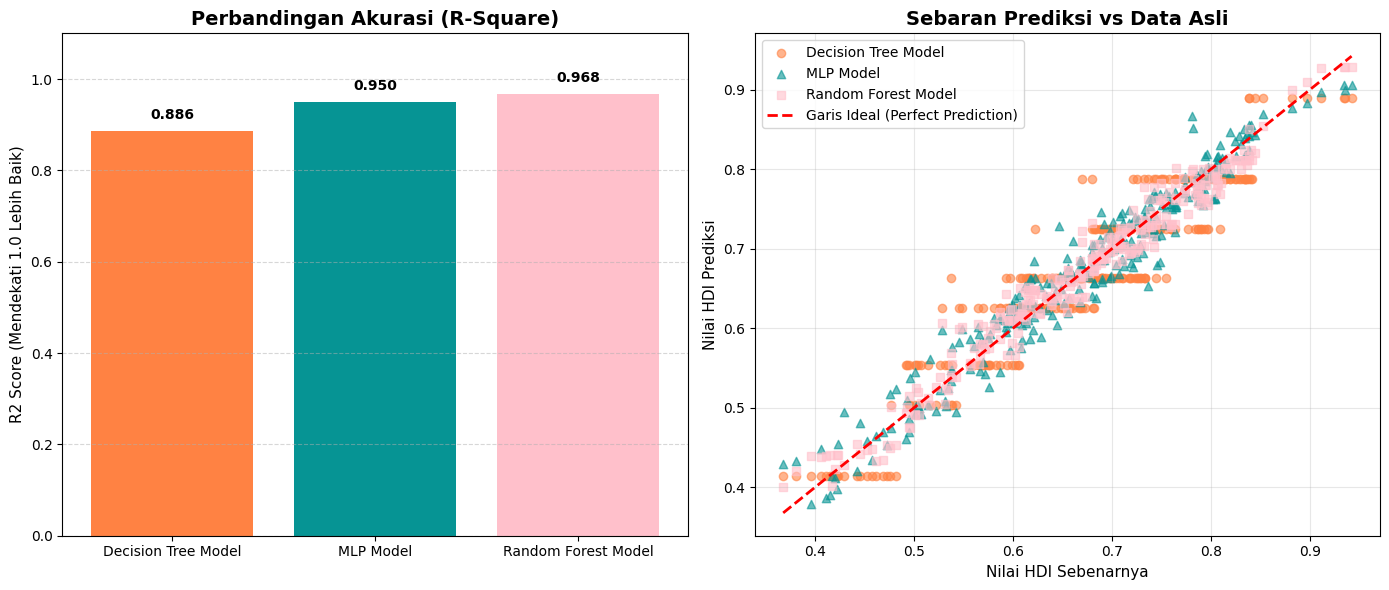

In [ ]:
# VISUALISASI PERBANDINGAN

plt.figure(figsize=(14, 6))

# Grafik Perbandingan R-Square (Bar Chart)
plt.subplot(1, 2, 1)
colors = ['#FF8243','#069494', '#FFC0CB']
bars = plt.bar(df_metrics['Model'], df_metrics['R2 Score'], color=colors)

plt.title('Perbandingan Akurasi (R-Square)', fontsize=14, fontweight='bold')
plt.ylabel('R2 Score (Mendekati 1.0 Lebih Baik)', fontsize=11)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Tambahkan label angka di atas batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{height:.3f}', ha='center', va='bottom', fontweight='bold')
plt.subplot(1, 2, 2)

# Plot titik-titik untuk setiap model
markers = ['o', '^', 's']
for i, (name, preds) in enumerate(model_results.items()):
    plt.scatter(actuals, preds, label=name, alpha=0.6, color=colors[i], marker=markers[i])

# Garis Ideal (Garis diagonal merah)
min_val = min(actuals.min(), min([p.min() for p in model_results.values()]))
max_val = max(actuals.max(), max([p.max() for p in model_results.values()]))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Garis Ideal (Perfect Prediction)')

plt.title('Sebaran Prediksi vs Data Asli', fontsize=14, fontweight='bold')
plt.xlabel('Nilai HDI Sebenarnya', fontsize=11)
plt.ylabel('Nilai HDI Prediksi', fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
